In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import math

def mostrar_resultados_test(ruta_carpeta, nombre_archivo, titulo):
    if not nombre_archivo:
        print(f"\n No se encontró archivo para: {titulo}")
        return

    ruta = os.path.join(ruta_carpeta, nombre_archivo)
    
    try:
        df = pd.read_csv(ruta)
        
        # Nos quedamos con la última fila (resultados finales)
        datos = df.iloc[-1]
        
        print("\n" + "-"*60)
        print(f"  {titulo.upper()}")
        print(f"    Archivo: {nombre_archivo}")
        print("-"*60)

        # Definimos las categorías basándonos en los prefijos de las columnas
        categorias = {
            "GLOBAL METRICS": "global_",
            "PRIMARY TASK": "primary_",
            "SECONDARY TASK": "secondary_",
            "MULTILABEL METRICS": "multilabel_"
        }

        # Iteramos por cada categoría para imprimir ordenadamente
        for nombre_cat, prefijo in categorias.items():
            # Filtramos las métricas que empiezan por el prefijo actual
            metricas_grupo = [k for k in datos.index if k.startswith(prefijo)]
            
            if metricas_grupo:
                print(f"\n{nombre_cat}")
                print(f"{'Metrica':<35} | {'Valor':<10}")
                print("-" * 50)
                
                for key in metricas_grupo:
                    valor = datos[key]
                    # Limpiamos el nombre: quitamos el prefijo y ponemos mayúsculas bonitas
                    nombre_limpio = key.replace(prefijo, "").replace("_", " ").title()
                    
                    # Formateo condicional: si es float lo mostramos con 4 decimales
                    if isinstance(valor, (float, int)):
                        val_str = f"{valor:.4f}"
                    else:
                        val_str = str(valor)
                        
                    print(f"  • {nombre_limpio:<31} : {val_str}")

        print("\n" + "═"*60 + "\n")

    except Exception as e:
        print(f"Error leyendo {nombre_archivo}: {e}")

def analizar_entrenamiento_y_test(ruta_carpeta):
    if not os.path.exists(ruta_carpeta):
        print(f"La ruta '{ruta_carpeta}' no existe.")
        return

    archivos = [f for f in os.listdir(ruta_carpeta) if f.endswith('.csv')]
    
    # 1. Identificar los archivos por nombre
    f_train = next((f for f in archivos if "train_train" in f), None)
    f_val   = next((f for f in archivos if "train_validation" in f), None)
    f_test  = next((f for f in archivos if "train_test" in f), None)
    f_sicap = next((f for f in archivos if "sicap_test" in f), None)

    # --- PARTE 1: GRÁFICAS EVOLUTIVAS (Train vs Validation) ---
    if f_train and f_val:
        print(f"Generando gráficas comparativas de:")
        print(f"   • Train: {f_train}")
        print(f"   • Val:   {f_val}\n")
        
        df_t = pd.read_csv(os.path.join(ruta_carpeta, f_train)).sort_values('epoch')
        df_v = pd.read_csv(os.path.join(ruta_carpeta, f_val)).sort_values('epoch')
        
        # Definir grupos de métricas para organizar las gráficas
        grupos_metricas = {
            "Multilabel Metrics": ['multilabel_subset_accuracy', 'multilabel_precision_micro', 'multilabel_recall_micro', 
                                   'multilabel_f1_micro', 'multilabel_precision_macro', 'multilabel_recall_macro', 
                                   'multilabel_f1_macro', 'multilabel_auroc_macro', 'multilabel_auprc_macro'],
            "Global Metrics": ['global_accuracy', 'global_precision', 'global_recall', 'global_f1', 'global_kappa'],
            "Primary Task": ['primary_accuracy', 'primary_precision', 'primary_recall', 'primary_f1', 'primary_kappa'],
            "Secondary Task": ['secondary_accuracy', 'secondary_precision', 'secondary_recall', 'secondary_f1', 'secondary_kappa'],
            
        }

        for nombre_grupo, columnas in grupos_metricas.items():
            # Filtrar columnas que realmente existen en el CSV
            cols_existentes = [c for c in columnas if c in df_t.columns and c in df_v.columns]
            
            if not cols_existentes:
                continue

            # Configuración de subplots (calculamos filas necesarias)
            n_cols = 3
            n_rows = math.ceil(len(cols_existentes) / n_cols)
            fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
            fig.suptitle(f'Evolución: {nombre_grupo} (Train vs Val)', fontsize=16)
            axes = axes.flatten()

            for i, col in enumerate(cols_existentes):
                ax = axes[i]
                ax.plot(df_t['epoch'], df_t[col], label='Train', marker='.', linestyle='-')
                ax.plot(df_v['epoch'], df_v[col], label='Validation', marker='.', linestyle='--')
                
                ax.set_title(col)
                ax.set_xlabel('Epoch')
                ax.set_ylabel('Valor')
                ax.legend()
                ax.grid(True, alpha=0.3)

            # Ocultar subplots vacíos si los hay
            for j in range(i + 1, len(axes)):
                axes[j].axis('off')

            plt.tight_layout(rect=[0, 0.03, 1, 0.95])
            plt.show()
    else:
        print("No se encontraron los archivos 'train_train' y 'train_validation' para graficar.")

    # --- PARTE 2: RESULTADOS FINALES (Test y Sicap) ---
    print("\n" + "="*80)
    print("RESULTADOS FINALES EN DATASETS DE PRUEBA")
    print("="*80)

    mostrar_resultados_test(ruta_carpeta, f_test, "TEST INTERNO (Train Test)")
    mostrar_resultados_test(ruta_carpeta, f_sicap, "TEST EXTERNO (SICAP)")

# --- EJECUCIÓN ---
analizar_entrenamiento_y_test("Y:\Shared_PFC-TFG-TFM\Activos\2024_2025\NataliaHidalgo\SICAP\results_multi_gpu2\model-CNN_frozen_MIL-attentionMIL_alpha_pe-0.01_alpha_pc-0.01_lrate-1e-05_wdecay-0.01_epochs-100_20251204_192147")

 *Starting General Configuration ...
Usando dispositivo: cuda


trainable params: 0 || all params: 414,259,969 || trainable%: 0.0
✓ Pesos cargados correctamente
Procesando WSIs: 100%|██████████| 10/10 [00:00<00:00, 1606.27it/s]
Loading embeddings for Inference ...
TEST: 100%|██████████| 3/3 [00:05<00:00,  1.85s/it]
 Cargando WSI desde: /workspace/data/slides_cropped/16B0003388_13.jpg 
 Scores de la slide [3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3] procesada.


/tmp/ipykernel_784402/3090431500.py:379: DeprecationWarning: BICUBIC is deprecated and will be removed in Pillow 10 (2023-07-01). Use Resampling.BICUBIC instead.
  orig = orig.resize(new_size, Image.BICUBIC)


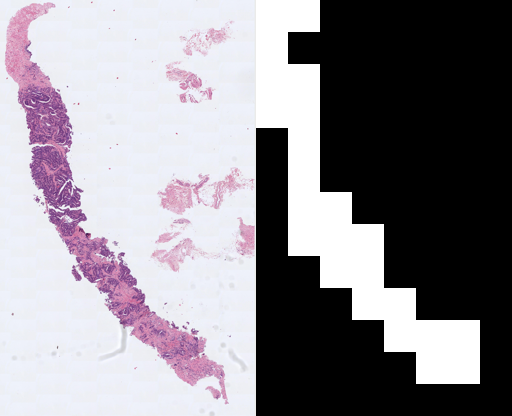

 Cargando WSI desde: /workspace/data/slides_cropped/16B0003394_1.jpg 
 Scores de la slide [3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3] procesada.


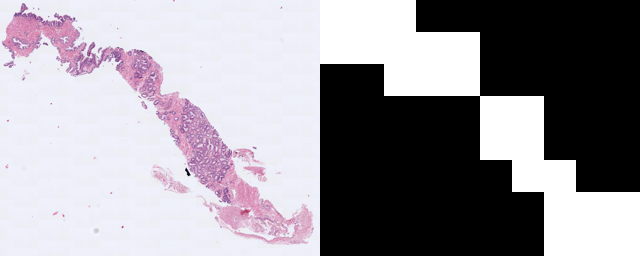

 Cargando WSI desde: /workspace/data/slides_cropped/16B0006668_3.jpg 
 Scores de la slide [3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3] procesada.


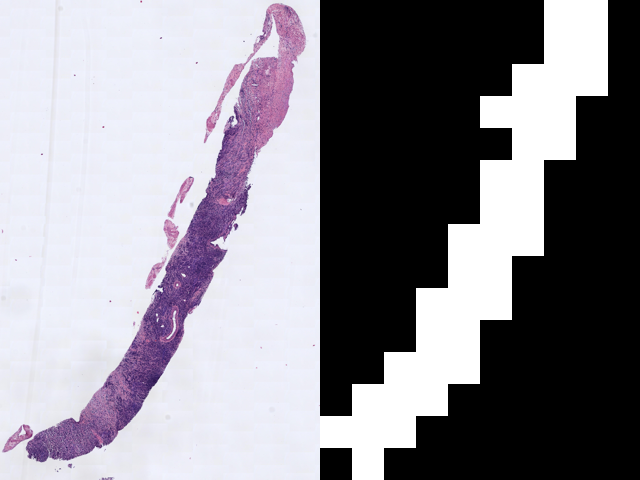

 Cargando WSI desde: /workspace/data/slides_cropped/16B0006694_1.jpg 
 Scores de la slide [3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3 3 3 3 3] procesada.


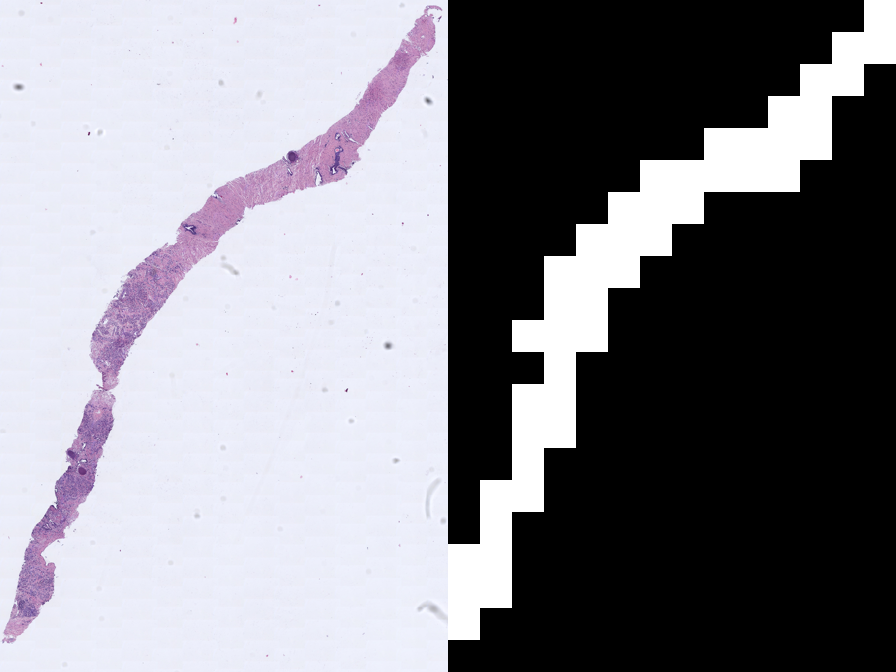

 Cargando WSI desde: /workspace/data/slides_cropped/16B0006695_3.jpg 
 Scores de la slide [3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3 3 3 3 3 3 3 3 3] procesada.


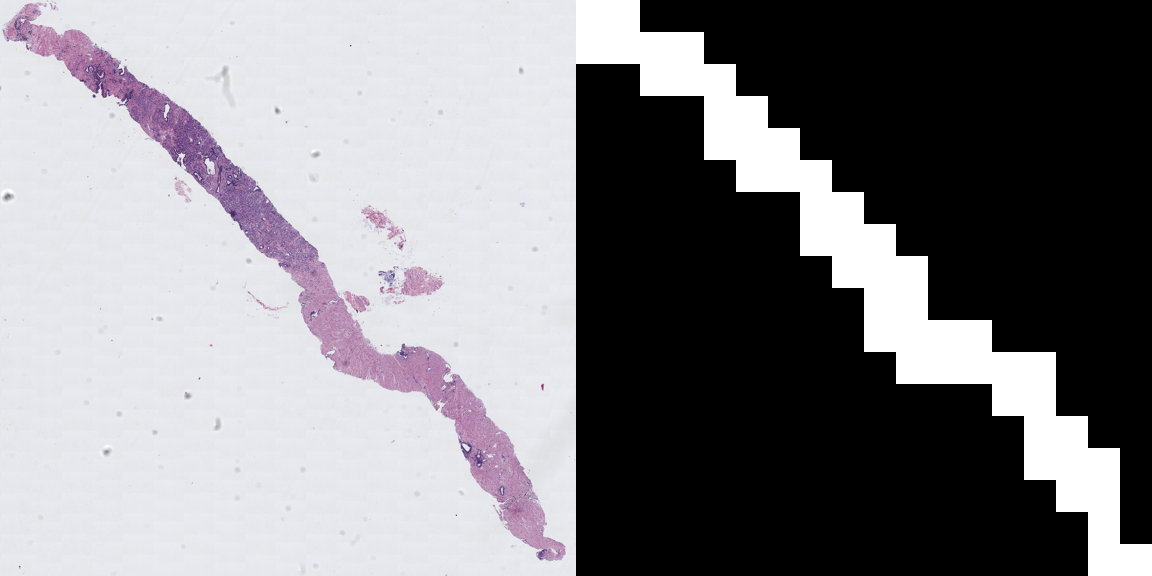

 Cargando WSI desde: /workspace/data/slides_cropped/16B0008066_0.jpg 
 Scores de la slide [3 3 3 3 3 3 3 3 3 3 3 3] procesada.


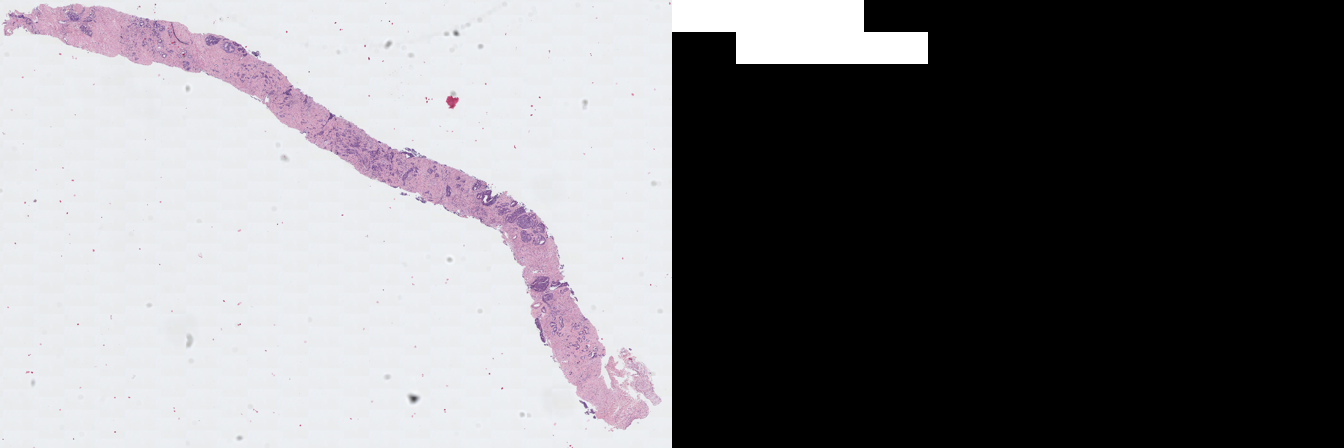

 Cargando WSI desde: /workspace/data/slides_cropped/16B0008067_0.jpg 
 Scores de la slide [3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3] procesada.


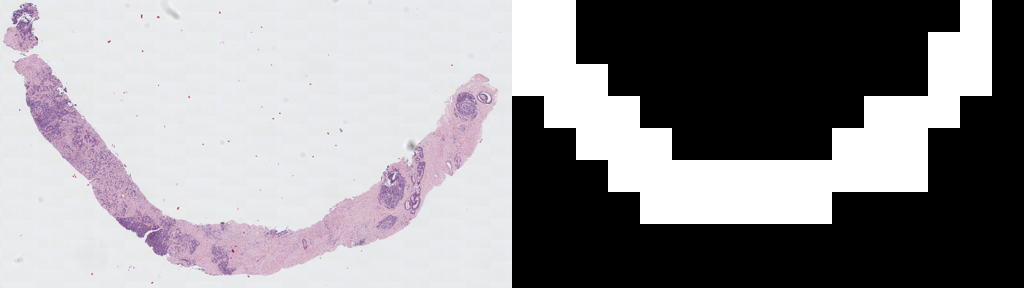

 Cargando WSI desde: /workspace/data/slides_cropped/16B0022610_9.jpg 
 Scores de la slide [3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3] procesada.


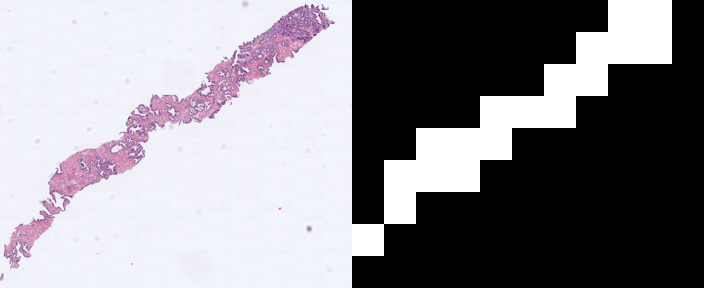

 Cargando WSI desde: /workspace/data/slides_cropped/16B0022612_1.jpg 
 Scores de la slide [3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3 3 3 3 3 3 3 3 3] procesada.


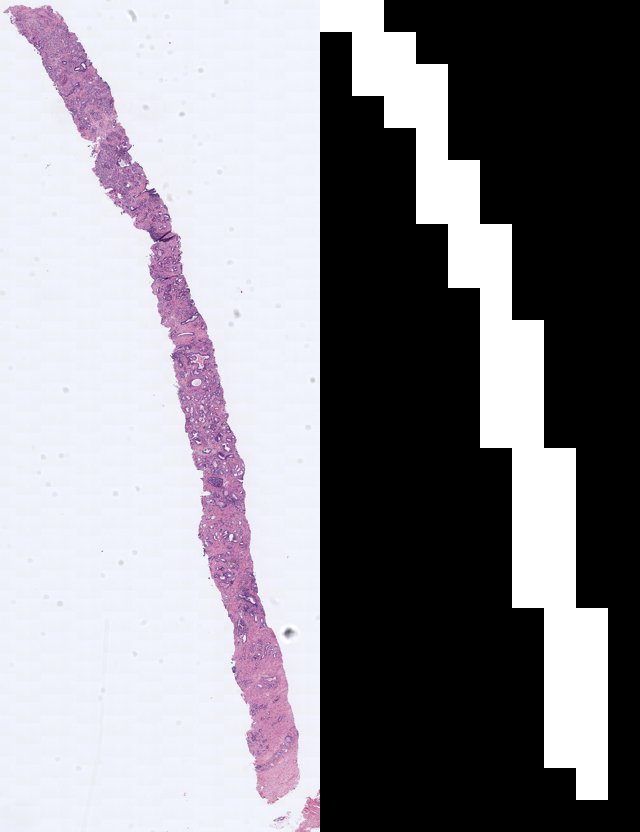

 Cargando WSI desde: /workspace/data/slides_cropped/16B0022613_2.jpg 
 Scores de la slide [3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3 3 3 3] procesada.


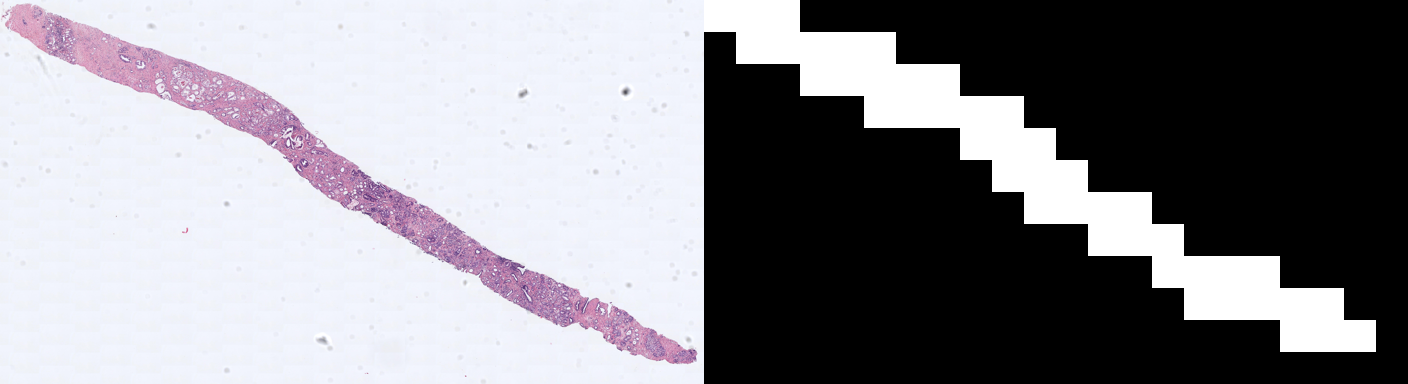

In [6]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms as T

import numpy as np
from PIL import Image
import os
import pandas as pd
import random
import sys 
from tqdm import tqdm 
import gc 
import h5py

from accelerate import Accelerator
from torch.cuda.amp import autocast
from safetensors.torch import load_file

# Directorio actual
current_dir  = os.path.abspath(os.getcwd())
sys.path.append(os.path.dirname(current_dir))

from utils.utils_train import  loss_restrictions, select_gleason_grades_from_batch_proportions, selecting_abs_threshold, selecting_prob_thresholds
from utils.utils_metrics import compute_all_gleason_metrics
from models.keep_model import get_keep_ia3_model, device


def create_file_label_df(images_path, data_path, NAME='', small_dataset=False, slide_col='image_id', num_samples=10):
    patch_list, patient_list = [], []
    gleason_score = []
    gleason_primary_list, gleason_secondary_list = [], []
    
    df = pd.read_excel(data_path)
    df = df.head(50) if small_dataset else df

    wsis = [f for f in os.listdir(images_path) if f.endswith('.h5')]

    # ---- 🔥 Seleccionar solo 10 WSIs ----
    wsis = wsis[:num_samples]      # usa los primeros
    # wsis = random.sample(wsis, num_samples)   # o aleatorios

    for f in tqdm(wsis, desc="Procesando WSIs", file=sys.stdout):
        slide_id = f.split('.h5')[0]
        if NAME == 'SICAP':
            slide_id = slide_id.split('_')[0]

        row = df[df[slide_col] == slide_id]
        if not row.empty:
            ruta_h5 = os.path.join(images_path, f)

            gleason = row[['gleason_score']].values.item()
            patient_id = row['patient_id'].values[0] if 'patient_id' in df.columns else row['image_id'].values[0]

            patch_list.append(ruta_h5)
            patient_list.append(patient_id)
            gleason_score.append(gleason)
            gleason_primary_list.append(row['gleason_primary'].values[0])
            gleason_secondary_list.append(row['gleason_secondary'].values[0])

    df_train = pd.DataFrame({
        'patch': patch_list,
        'patients': patient_list,
        'gleason_score': gleason_score,
        'gleason_primary': gleason_primary_list,
        'gleason_secondary': gleason_secondary_list
    })

    return df_train

class RAM_WSI_Dataset(Dataset):
    def __init__(self, dataframe, indices, random_subsets=False, len_subset=1000):
        gc.collect()
        self.dataframe = dataframe
        self.indices = list(indices)
        self.random_subsets = bool(random_subsets)

        if self.random_subsets:
            self.len_subset = min(int(len_subset), len(self.indices))
        else:
            self.len_subset = len(self.indices)

        self.transform = T.Compose([
            T.Resize(size=224, interpolation=T.InterpolationMode.BICUBIC),
            T.CenterCrop(size=(224, 224)),
            T.ToTensor(),
            T.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
        ])

        self.patch_id, self.images, self.labels, self.coords = [],[], [], []

        for i in tqdm(self.indices, desc="Loading WSI", file=sys.stdout):
            row = self.dataframe.iloc[i]

            label = torch.tensor(
                [row['gleason_primary_mapped'], row['gleason_secondary_mapped']],
                dtype=torch.long
            )
            self.labels.append(label)

            with h5py.File(row['patch'], "r", swmr=True) as h5_file:
                imgs = h5_file["imgs"][:]        # (N, H, W, C)
                coords = h5_file["coords"][:]    # (N, 2)

                if imgs.shape[0] <= 1:
                    continue
            imgs = torch.stack([self.transform(Image.fromarray(img).convert('RGB')) for img in imgs])
            self.patch_id.append(row['patch'])
       
            self.images.append(imgs)
            self.coords.append(coords)

    def __len__(self):
        return self.len_subset

    def __getitem__(self, idx):
        patch_id = self.patch_id[idx]
        imgs = self.images[idx]
        coords = self.coords[idx]
        label = self.labels[idx]

        return patch_id,imgs, coords, label
    
def collate_fn(batch):
    patch_id,features,coords, labels = zip(*batch)
    list_patch_id = list(patch_id)
    list_features = list(features) # features: tuple de tensores de distinta longitud -> devolvemos como lista
    list_coords = list(coords)
    labels = torch.stack(labels, dim=0) # Convertir labels a tensor
    return list_patch_id,list_features, list_coords, labels

def run_epoch(model, dataloader, device, accelerator, 
              loss_BCE, optimizer=None, 
              args=None, mode="train"):

    assert mode in ["train", "val", "test"], "mode debe ser 'train', 'val' o 'test'."

    # Acumuladores métricas
    all_y_true_primary, all_y_true_secondary = [], []
    all_y_pred_primary, all_y_pred_secondary = [], []
    all_probs, all_y_true_onehot = [], []
    all_wsi_proportions = []

    # Para TEST → guardar coords + scores + patches
    test_outputs = []   # ← NUEVO

    total_loss_sum = 0.0
    total_seen = torch.tensor(0, device=device)

    model.train() if mode == "train" else model.eval()
    torch.set_grad_enabled(mode == "train")

    for (patch_id, patch_imgs, coords, y) in tqdm(
        dataloader, desc=f"{mode.upper()}",
        disable=not accelerator.is_local_main_process,
        file=sys.stdout
    ):
        """
        patch_imgs:   (B, N_patches, 3, 224, 224)
        coords:       list de B arrays  [N_patches, 2]
        y:            (B,2)
        slide_ids:    lista de strings
        """

        y_primary = y[:, 0].to(device)
        y_secondary = y[:, 1].to(device)
        y = y.to(device)

        # One-hot
        y_onehot = torch.zeros(y.shape[0], 4, device=device)
        y_onehot.scatter_(1, y, 1)

        #with torch.no_grad() if mode == "test" else autocast(dtype=torch.float16):

            # --- Forward ---
        with autocast(dtype=torch.float16):
        
            wsi_prediction, patch_predictions = model(patch_imgs)
            # wsi_prediction: (B,4)
            # patch_predictions: list of B tensors → (N_i,4)

        # Proporciones
        wsi_proportions = torch.stack([
            p.mean(dim=0) if p.numel() > 0 else torch.zeros(
                wsi_prediction.size(1), device=wsi_prediction.device)
            for p in patch_predictions
        ], dim=0)

        # Pérdida
        loss = loss_BCE(wsi_prediction, y_onehot)
        loss_pe_pc = loss_restrictions(wsi_proportions, 0.01, 0.01)
        total_loss = loss + loss_pe_pc

        if mode == "train":
            optimizer.zero_grad()
            accelerator.backward(total_loss)
            accelerator.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

        batch_sz = len(patch_imgs)
        total_seen += batch_sz
        total_loss_sum += accelerator.gather(total_loss.detach() * batch_sz).sum().item()

        # Predicción primaria/secundaria
        pred_primary, pred_secondary = select_gleason_grades_from_batch_proportions(
            wsi_proportions, 0.3)

        # Guardar para métricas
        all_y_true_primary.append(y_primary.cpu())
        all_y_true_secondary.append(y_secondary.cpu())
        all_y_pred_primary.append(pred_primary.cpu())
        all_y_pred_secondary.append(pred_secondary.cpu())
        all_y_true_onehot.append(y_onehot.cpu())
        all_probs.append(wsi_prediction.detach().cpu())

        # 
        if mode == "test":
            #print(f" Type slide_id: {patch_id} | Shape coords: {coords[0].shape} | shape patch_predictions: {patch_predictions[0].shape} ")
            for i in range(batch_sz):
                slide_out = {
                    "slide_id": patch_id[i],
                    "coords": coords[i],
                    "scores": torch.argmax(patch_predictions[i], dim=1).cpu().numpy(), ###
                    }
                test_outputs.append(slide_out)

    # ---- MÉTRICAS ----
    total_seen = accelerator.reduce(total_seen, reduction="sum").item()
    epoch_loss = total_loss_sum / total_seen

    y_true1 = torch.cat(all_y_true_primary).numpy()
    y_true2 = torch.cat(all_y_true_secondary).numpy()
    y_pred1 = torch.cat(all_y_pred_primary).numpy()
    y_pred2 = torch.cat(all_y_pred_secondary).numpy()
    probs = torch.cat(all_probs).numpy()
    y_onehot = torch.cat(all_y_true_onehot).numpy()

    '''metrics = compute_all_gleason_metrics(
        y_true_primary=y_true1,
        y_pred_primary=y_pred1,
        y_true_secondary=y_true2,
        y_pred_secondary=y_pred2,
        y_true_onehot=y_onehot,
        y_probs=probs,
        y_prob_thresh=0.4
    )'''
    metrics={}

    if mode == "val":
        val_metrics, y_prob_threshold = selecting_prob_thresholds(
            y_true1, y_pred1, y_true2, y_pred2, y_onehot, probs
        )
        metrics_global, tumor_abs_threshold = selecting_abs_threshold(
            all_wsi_proportions, y_true1, y_true2
        )
        return metrics, epoch_loss, y_prob_threshold, tumor_abs_threshold

    if mode == "test":
        # 🔥 En test devolvemos test_outputs para hacer heatmaps
        test_outputs= pd.DataFrame(test_outputs)
        return metrics, epoch_loss, test_outputs

    return metrics, epoch_loss

def build_heatmap(coords, scores, patch_size=512, scale_factor=16, save_path=None):
    """
    coords: Nx2 array (x, y)
    scores: N array (peso o score por patch)
    save_path: path para guardar el heatmap
    """

    # Escalar coordenadas
    coords = coords // scale_factor
    patch_size = patch_size // scale_factor
    max_x, max_y = coords[:, 0].max(), coords[:, 1].max()
    min_x, min_y = coords[:, 0].min(), coords[:, 1].min()

    width, height = max_x - min_x + 1, max_y - min_y + 1

    shifted_coords = coords.copy()
    shifted_coords[:, 0] -= min_x
    shifted_coords[:, 1] -= min_y

    # Inicializar heatmap
    heatmap = np.zeros((height + patch_size, width + patch_size), dtype=float)

    # Añadir valores por patch
    for (x, y), w in zip(shifted_coords, scores):
        heatmap[y:y+patch_size, x:x+patch_size] += w

    # Normalizar
    if heatmap.max() > 0:
        heatmap = heatmap / heatmap.max()

    heatmap = (255 * heatmap).astype(np.uint8)
    img = Image.fromarray(heatmap, mode="L")

    if save_path:
        img.save(save_path)

    return img
from PIL import Image

def show_side_by_side(left_img, right_img):
    """
    left_img: PIL.Image → imagen real
    right_img: PIL.Image → heatmap
    """

    w, h = left_img.size

    # Crear un lienzo que tenga el doble de ancho
    canvas = Image.new("RGB", (w * 2, h))

    # Pegar imágenes
    canvas.paste(left_img, (0, 0))
    canvas.paste(right_img, (w, 0))

    return canvas

# -----------------------------------------------------------------------------------------------------------------------

data_sicap_patches='/workspace/data/features_SICAP/patches'
data_sicap_path='/workspace/data/wsi_labels_changed_SICAP.xlsx'

print(" *Starting General Configuration ...")
CUDA_LAUNCH_BLOCKING=1
use_amp = torch.cuda.is_available()  # mixed precision if GPU available

accelerator = Accelerator()
device = accelerator.device
print(f"Usando dispositivo: {device}", flush = True)

model = get_keep_ia3_model(clasification_model = 'graph',pretrain=False )
ckpt_path = "/workspace/results/try_0.0001_16_10_opt_threshold/best_model"
accelerator.load_state(ckpt_path)
model = torch.nn.SyncBatchNorm.convert_sync_batchnorm(model)
print("✓ Pesos cargados correctamente")

#cargar este modleo estos pssos
loss = nn.BCELoss() #WithLogitsLoss(pos_weight=sum_weights) 
df_test = create_file_label_df(data_sicap_patches, data_sicap_path, NAME = 'SICAP')

label_mapping = {0: 0, 1: 0, 2: 0, 3: 1, 4: 2, 5: 3}
df_test['gleason_primary_mapped'] = df_test['gleason_primary'].map(label_mapping)
df_test['gleason_secondary_mapped'] = df_test['gleason_secondary'].map(label_mapping)
df_test['gleason_score'] = df_test['gleason_score'].astype(int)

print("Loading embeddings for Inference ...")
inference_loader = DataLoader(RAM_WSI_Dataset(df_test, df_test.index), shuffle=False, batch_size=4, collate_fn=collate_fn)
model, inference_loader = accelerator.prepare(  model, inference_loader )
inference_metrics, inference_loss, test_outputs= run_epoch(model, inference_loader, device, accelerator, loss, None, mode='test')   

'''print(f" Test Loss: {inference_loss:.4f}  Acc_global: {inference_metrics['global'][0]:.4f} Kappa_global: {inference_metrics['global'][-1]:.4f} | Acc_primary: {inference_metrics['primary'][0]:.4f} Kappa_primary: {inference_metrics['primary'][-1]:.4f} |Acc_secondary: {inference_metrics['secondary'][0]:.4f} Kappa_secondary: {inference_metrics['secondary'][-1]:.4f}\n")
print(f"Acuracy: {inference_metrics[0]}, | Precision: {inference_metrics[1]} | Recall : {inference_metrics[2]}| F1 Score: {inference_metrics[3]}")
print(f"Métricas : {inference_metrics}")'''

for index, row in test_outputs.iterrows():
    #print(test_outputs.head(2))
    slide_id = row['slide_id']
    
    heatmap = build_heatmap(
        row['coords'],
        row['scores'],
        patch_size=512,
        scale_factor=16,
        save_path=None
    )
    
    slide_id = slide_id.replace('.h5','') + '.jpg'  # Ajustar extensión si es necesario
    wsi_path = os.path.join('/workspace/data/slides_cropped',slide_id.split('/')[-1])
    print(f" Cargando WSI desde: {wsi_path} ")
    print(f" Scores de la slide {row['scores']} procesada.")
    orig = Image.open(wsi_path)
    w, h = orig.size
    new_size = (w // 16, h // 16)
    orig = orig.resize(new_size, Image.BICUBIC)
    
    #img.show(title=f"Heatmap for slide {slide_id}")
    combined = show_side_by_side(orig, heatmap)
    combined.show(title=f"Heatmap for slide {slide_id.split('/')[-1]}")

In [7]:
# FUNCIONS
import torch
from torchvision import transforms as T
from torch.utils.data import Dataset
import pandas as pd
import os
import numpy as np
import h5py
from tqdm import tqdm 
import gc
from PIL import Image
import sys

# Directorio actual
current_dir  = os.path.abspath(os.getcwd())
sys.path.append(os.path.dirname(current_dir))
from utils.utils_train import loss_restrictions, select_gleason_grades_from_batch_proportions, selecting_abs_threshold, selecting_prob_thresholds
from utils.utils_metrics import compute_all_gleason_metrics

def create_file_label_df(images_path, data_path, NAME='', slide_col='image_id', small_dataset_for_test = False):
    features_list,patient_list  = [], []
    gleason_score, gleason_primary_list, gleason_secondary_list= [], [],[]

    df = pd.read_excel(data_path)
    df = df.head(500) if small_dataset_for_test else df

    wsis = [f for f in os.listdir(images_path) if f.endswith('.h5')]
    for f in tqdm(wsis, desc="Procesando WSIs", file=sys.stdout):
        slide_id = f.split('.h5')[0]
        if NAME == 'SICAP':
            slide_id = slide_id.split('_')[0]
        row = df[df[slide_col] == slide_id]

        if not row.empty:
            ruta_h5 = os.path.join(images_path, f)
         
            features = ruta_h5
            gleason = row[['gleason_score']].values
            if 'patient_id' in df.columns:
                patient_select=row['patient_id'].values
            else:
                patient_select = row['image_id'].values

            gleason_score.append(gleason.item())
            features_list.append(features)
            patient_list.append(patient_select)
            gleason_primary_list.append(row['gleason_primary'].values[0])
            gleason_secondary_list.append(row['gleason_secondary'].values[0])

    df_train = pd.DataFrame({
        'features': features_list,
        'patients':patient_list,
        'gleason_score': gleason_score,
        'gleason_primary': gleason_primary_list,
        'gleason_secondary': gleason_secondary_list
    })

    return df_train

class WSI_Dataset(Dataset):
    """
    Dataset de WSI con opción de precarga completa en CPU o lectura on-demand.

    Args:
        dataframe (pd.DataFrame)
        indices (list[int]): Lista de índices del DataFrame.
        random_subsets (bool): Si True, en cada época se usa un subset aleatorio de tamaño len_subset.
                               Si False, se usa todo el dataset (validación/test).
        len_subset (int): Tamaño del subset aleatorio que se usará en cada época.
                          Si es mayor que el total, se ajusta automáticamente.
        load_on_demand (bool): 
            - False => Precarga todas las imagenes en CPU.
            - True  => no precargar imágenes; lectura en __getitem__.
    """
    def __init__(self, dataframe, indices, random_subsets=False, len_subset=1000, load_on_demand=False, inference_heatmap=False):
        gc.collect()
        self.dataframe = dataframe
        self.indices = list(indices)
        self.random_subsets = bool(random_subsets)
        self.load_on_demand = bool(load_on_demand)
        self.inference_heatmap = bool(inference_heatmap)

        # Ajustar tamaño del subset
        if self.random_subsets:
            self.len_subset = min(int(len_subset), len(self.indices))
        else:
            self.len_subset = len(self.indices)

        # Transformaciones estándar
        self.transform = T.Compose([
            T.ToTensor(),
            T.Resize((224, 224),antialias=True),
            T.Normalize(mean=[0.485, 0.456, 0.406], # ImageNet Normalization Values
                       std=[0.229, 0.224, 0.225])
        ])

        # Etiquetas (se precargan siempre por su bajo coste en memoria)
        self.patch_id, self.images, self.labels, self.coords = [],[],[],[]
        
        for i in self.indices:
            row = self.dataframe.iloc[i]
            label = torch.tensor(
                [row['gleason_primary_mapped'], row['gleason_secondary_mapped']],
                dtype=torch.long
            )
            self.labels.append(label)

        # Si NO estamos en modo load_on_demand, precargar imágenes
        if not self.load_on_demand:
            
            for i in tqdm(self.indices, desc="Loading WSI", file=sys.stdout):
                row = self.dataframe.iloc[i]
                features_path = row['features']
                with h5py.File(features_path, "r", swmr=True) as h5_file:
                    imgs = h5_file["imgs"][:]  # numpy array
                    if inference_heatmap:
                        coords = h5_file["coords"][:]  # numpy array

                imgs_tensor = torch.stack([
                    self.transform(Image.fromarray(img)) for img in imgs
                ])
                self.patch_id.append(row['features'])
                self.images.append(imgs_tensor)
                self.coords.append(coords if inference_heatmap else None)
        else:
            # En modo load_on_demand sólo guardamos rutas
            self.feature_paths = [self.dataframe.iloc[i]['features'] for i in self.indices]

        # Mapeo índice original → posición en listas
        self.idx2pos = {orig_idx: pos for pos, orig_idx in enumerate(self.indices)}

        # Inicializar subset
        if self.random_subsets:
            self.ind_subset = None
            self.update_random_subset()
        else:
            self.ind_subset = self.indices

    def update_random_subset(self):
        if self.random_subsets:
            self.ind_subset = np.random.choice(self.indices, self.len_subset, replace=False)

    def get_current_subset_indices(self):
        return list(self.ind_subset)

    def __len__(self):
        return len(self.ind_subset)

    def __getitem__(self, idx):
        """
        Si load_on_demand=True => lectura on-demand desde el .h5.
        Si load_on_demand=False => devuelve las imagenes en tensores precargados.
        """
        if self.random_subsets:
            orig_idx = int(self.ind_subset[idx])
            pos = self.idx2pos[orig_idx]
        else:
            pos = idx

        patch_id = self.patch_id[pos] 
        label = self.labels[pos]
        coords = self.coords[pos] 

        # MODO PRECARGA CPU
        if not self.load_on_demand:
            if self.inference_heatmap:
                return patch_id, self.images[pos], label, coords
            else:
                return self.images[pos], label

        # MODO GPU-LIKE: carga desde HDF5 en cada __getitem__
        feature_path = self.feature_paths[pos]
        with h5py.File(feature_path, "r") as h5_file:
            imgs = h5_file["imgs"][:]  # numpy array

        imgs_tensor = torch.stack([
            self.transform(Image.fromarray(img)) for img in imgs
        ])

        if self.inference_heatmap:
                return patch_id, imgs_tensor, label, coords
        else:
            return imgs_tensor, label


def collate_fn(batch):
    """
    batch: lista de tuples (patch_id, features_tensor, label_tensor, coords)
    - patch_id: identificador del WSI
    - features_tensor: Tensor [num_patches, C, H, W] (varía por WSI)
    - label_tensor: Tensor con las etiquetas (ej. [primary, secondary])
    - coords: coordenadas de los parches
    Devuelve:
    - list_patch_id: list de patch_id (uno por WSI)
    - list_features: list de tensores (uno por WSI)
    - labels: tensor [batch_size, ...]
    - list_coords: list de tensores de coordenadas (uno por WSI)
    """
       
    patch_ids, features, labels, coords = zip(*batch)
    # features: tuple de tensores de distinta longitud -> devolvemos como lista
    list_patch_id = list(patch_ids)
    list_features = list(features)
    list_coords = list(coords)
    labels = torch.stack(labels, dim=0)

    return list_patch_id, list_features, labels, list_coords

def run_epoch(model, dataloader, device, accelerator, 
              loss_BCE, optimizer=None, 
              args=None, mode="train",inference_heatmap = False,
              y_prob_threshold=None, tumor_abs_threshold=None, alpha_pe=0, alpha_pc=0):
    """
    Ejecuta una época completa (train, val o test) y devuelve métricas y pérdida media.

    Args:
        model: modelo PyTorch.
        dataloader: iterable de batches (inputs, labels).
        device: dispositivo ('cuda' o 'cpu').
        accelerator: objeto de aceleración de HuggingFace.
        loss_BCE: función de pérdida binaria (nn.BCELoss).
        optimizer: optimizador (solo requerido si mode='train').
        args: argumentos con alpha_pe y alpha_pc.
        mode (str): 'train', 'val' o 'test'.
        y_prob_threshold (float): umbral de probabilidad para clasificación multilabel. Si es None, se usa args.y_prob_threshold.
        tumor_abs_threshold (float): umbral absoluto de proporción tumoral. Si es None, se usa args.tumor_abs_threshold.

    Returns:
        dict: métricas calculadas.
        float: pérdida media de la época.
    """
    assert mode in ["train", "val", "test"], "mode debe ser 'train', 'val' o 'test'."

    # Acumuladores
    all_y_true_primary, all_y_true_secondary = [], []
    all_y_pred_primary, all_y_pred_secondary = [], []
    all_probs, all_y_true_onehot = [],[]
    all_wsi_proportions = []

    test_output = []
    total_loss_sum = 0.0
    total_seen = torch.tensor(0, device=device)
    
    # Umbrales por defecto si no se proporcionan
    if y_prob_threshold is None and tumor_abs_threshold is None:
        y_prob_threshold = args.y_prob_threshold
        tumor_abs_threshold = args.tumor_abs_threshold
    if alpha_pc is None and alpha_pe is None:
        alpha_pe = args.alpha_pe
        alpha_pc = args.alpha_pc

    # Modo del modelo
    model.train() if mode == "train" else model.eval()

    # Desactivar gradientes si no es entrenamiento
    torch.set_grad_enabled(mode == "train")
    
    for batch_info in tqdm(dataloader, desc=f"{mode.upper()}", disable=not accelerator.is_local_main_process, file=sys.stdout):
        # inputs: list of tensors [N_patches, C, H, W]
        # y: tensor [batch, 2]
        if inference_heatmap:
            patch_id, inputs, y, coords = batch_info
        else:
            inputs, y = batch_info

        # Mover etiquetas al device
        y_primary = y[:, 0].to(device)
        y_secondary = y[:, 1].to(device)
        y = y.to(device)

        # One-hot multi-label (primary + secondary)
        y_onehot = torch.zeros(y.shape[0], 4, device=device)
        y_onehot.scatter_(1, y, 1)

        # --- Forward ---
        # (El modelo mueve internamente los inputs al device)
        wsi_prediction, patchs_prediction = model(inputs) # wsi_prediction: Tensor (B,4) , patchs_prediction: list of B tensors, cada uno (N_patches,4)

        # --- Cálculo de proporciones por WSI (media de probabilidades por parche) ---
        # Si algún WSI tuviera 0 parches, usamos vector ceros (Aunque eso debería evitarse)
        wsi_proportions = torch.stack([
            p.mean(dim=0) if p.numel() > 0 else torch.zeros(wsi_prediction.size(1), device=wsi_prediction.device)
            for p in patchs_prediction
        ], dim=0)  # (B,4)

        # --- Cálculo de pérdidas ---
        loss = loss_BCE(wsi_prediction, y_onehot)
        loss_pe_pc = loss_restrictions(wsi_proportions, alpha_pe, alpha_pc)
        total_loss = loss + loss_pe_pc

        # --- Backpropagation ---
        if mode == "train":
            optimizer.zero_grad()
            accelerator.backward(total_loss)
            accelerator.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

        # --- Acumulación de pérdidas ---
        batch_sz = len(inputs)
        total_seen += batch_sz
        total_loss_sum += accelerator.gather(total_loss.detach() * batch_sz).sum().item()

        # --- Predicciones (selección de primary/secondary a partir de proporciones) ---
        if mode =='val':
            all_wsi_proportions.append(wsi_proportions.detach().cpu())
                           
        pred_primary, pred_secondary = select_gleason_grades_from_batch_proportions(wsi_proportions, tumor_abs_threshold)

        # --- Probabilidades asociadas ---
        probs = wsi_prediction.detach().cpu()
        # --- Acumuladores para métricas ---
        all_y_true_primary.append(y_primary.detach().cpu())
        all_y_true_secondary.append(y_secondary.detach().cpu())
        all_y_pred_primary.append(pred_primary.detach().cpu())
        all_y_pred_secondary.append(pred_secondary.detach().cpu())
        all_y_true_onehot.append(y_onehot.detach().cpu())
        all_probs.append(probs)

        if inference_heatmap:
            for i in range(batch_sz):
                slide_out = {
                    "slide_id": patch_id[i],
                    "coords": coords[i],
                    "scores": torch.argmax(patchs_prediction[i], dim=1).cpu().numpy(), ###
                    }
                test_output.append(slide_out)

    # --- Métricas de la época ---
    total_seen = accelerator.reduce(total_seen, reduction="sum").item()
    epoch_loss = total_loss_sum / total_seen

    # Concatenar todo
    y_true1 = torch.cat(all_y_true_primary).numpy()
    y_true2 = torch.cat(all_y_true_secondary).numpy()
    y_pred1 = torch.cat(all_y_pred_primary).numpy()
    y_pred2 = torch.cat(all_y_pred_secondary).numpy()
    probs = torch.cat(all_probs).numpy()
    y_onehot = torch.cat(all_y_true_onehot).numpy()

    # --- Calcular métricas ---
    metrics = compute_all_gleason_metrics(
        y_true_primary=y_true1,
        y_pred_primary=y_pred1,
        y_true_secondary=y_true2,
        y_pred_secondary=y_pred2,
        y_true_onehot=y_onehot,
        y_probs=probs,y_prob_threshold = y_prob_threshold)
    
    if mode == 'val':
        val_metrics, y_prob_threshold= selecting_prob_thresholds(y_true1, y_pred1, y_true2, y_pred2, y_onehot, probs)
        metrics_global, tumor_abs_threshold=selecting_abs_threshold(all_wsi_proportions,y_true1, y_true2)
        return metrics, epoch_loss, y_prob_threshold, tumor_abs_threshold
    if inference_heatmap:
        test_output= pd.DataFrame(test_output)
        return metrics, epoch_loss, test_output
    else:
        return metrics, epoch_loss
    

def build_heatmap(coords, scores, patch_size=512, scale_factor=16, save_path=None):
    """
    coords: Nx2 array (x, y)
    scores: N array con valores 0,1,2,3
    Produce heatmap en RGB con colores fijos por clase.
    """

    # Escalar coordenadas
    coords = coords // scale_factor
    patch_size = patch_size // scale_factor

    max_x, max_y = coords[:, 0].max(), coords[:, 1].max()
    min_x, min_y = coords[:, 0].min(), coords[:, 1].min()

    width  = max_x - min_x + 1
    height = max_y - min_y + 1

    # Ajustar coordenadas
    shifted_coords = coords.copy()
    shifted_coords[:, 0] -= min_x
    shifted_coords[:, 1] -= min_y

    # Heatmap RGB
    heatmap = np.zeros((height + patch_size, width + patch_size, 3), dtype=np.uint8)

    # Mapa de colores
    color_map = {
        3: (255,   0,   0),   # Rojo
        2: (255, 128,   0),   # Naranja
        1: (255, 255,   0),   # Amarillo
        0: (  0,   0, 255)    # Azul
    }

    # Dibujar los parches según su score en color sólido
    for (x, y), s in zip(shifted_coords, scores):
        color = color_map.get(int(s), (255, 255, 255))  # Blanco si algo raro
        heatmap[y:y+patch_size, x:x+patch_size] = color

    img = Image.fromarray(heatmap, mode="RGB")

    if save_path:
        img.save(save_path)

    return img

from PIL import Image, ImageDraw


def overlay_heatmap_on_image(orig, heatmap, alpha=0.45):
    """Devuelve el overlay del heatmap sobre la imagen original."""
    if heatmap.mode != "RGB":
        heatmap = heatmap.convert("RGB")
    
    heatmap_resized = heatmap.resize(orig.size)
    # Asegurar que el heatmap sea RGB
    
    return Image.blend(orig, heatmap_resized, alpha)

def draw_gt_patches(orig, df_gt, slide_id, patch_size=512, scale_factor=16):
    """
    Colorea los parches GT sobre la imagen original con transparencia.
    """
    alpha = 80
    # Colores clase → RGB
    COLOR_MAP = {
        5: (255, 0, 0, alpha),      # Rojo
        4: (255, 140, 0, alpha),    # Naranja
        4.5: (255, 140, 0, alpha),    # Naranja
        3: (255, 255, 0, alpha),    # Amarillo
        0: (0, 0, 255, alpha),      # Azul
    }
    slide_id = slide_id.split('.')[0]
    df_slide = df_gt[df_gt["Slide_ID"] == slide_id]

    # Convertir imagen a RGBA para permitir alpha
    orig = orig.convert("RGBA")

    # Capa transparente donde dibujar los colores
    overlay = Image.new("RGBA", orig.size, (0, 0, 0, 0))
    draw = ImageDraw.Draw(overlay)

    ps = patch_size // scale_factor

    for _, row_gt in df_slide.iterrows():
        x = int(row_gt["X"] // scale_factor)
        y = int(row_gt["Y"] // scale_factor)
        val = int(row_gt["Valor_Mask"])

        if val not in COLOR_MAP:
            continue
        
        color = COLOR_MAP[val]  # rgba con alpha

        # Dibujar parche transparente
        draw.rectangle([x, y, x + ps, y + ps], fill=color)

    # Combinar overlay de parches con la imagen original
    blended = Image.alpha_composite(orig, overlay)

    return blended.convert("RGB")

In [ ]:
# IMPORT LIBRARIES
import os 
import sys
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from PIL import Image
import pandas as pd 
from accelerate import Accelerator

current_dir  = os.path.abspath(os.getcwd())# Directorio actual
sys.path.append(os.path.dirname(current_dir))
from models.keep_model import get_keep_ia3_model

# DEFINE PATHS 
ckpt_path = "/workspace/results/try_0.0001_16_10_opt_threshold/best_model"
result_path = "/workspace/data/patch_coord_2.xlsx"
folder_original_imgs = '/workspace/data/slides_filter'
num_img_show = 10
sicap_images_folder_path = '/workspace/data/features_SICAP/patches'
sicap_labels_df_path    = '/workspace/data/wsi_labels_changed_SICAP.xlsx'

# GENERAL CONFIGURATION 
print(" *Starting General Configuration ...")
CUDA_LAUNCH_BLOCKING=1
use_amp = torch.cuda.is_available()  # mixed precision if GPU available

accelerator = Accelerator()
device = accelerator.device
print(f"Usando dispositivo: {device}", flush = True)

# LOADING MODEL 
model = get_keep_ia3_model(clasification_model = 'graph',pretrain=False )
accelerator.load_state(ckpt_path)
model = torch.nn.SyncBatchNorm.convert_sync_batchnorm(model)
print("✓ Pesos cargados correctamente")

loss = nn.BCELoss() 
# LOADING DATA
df_test = create_file_label_df(sicap_images_folder_path, sicap_labels_df_path, NAME = 'SICAP')

label_mapping = {0: 0, 1: 0, 2: 0, 3: 1, 4: 2, 5: 3}
df_test['gleason_primary_mapped'] = df_test['gleason_primary'].map(label_mapping)
df_test['gleason_secondary_mapped'] = df_test['gleason_secondary'].map(label_mapping)
df_test['gleason_score'] = df_test['gleason_score'].astype(int)

print("Loading embeddings for Inference ...")
inference_loader = DataLoader(WSI_Dataset(df_test, df_test.index, inference_heatmap=True), shuffle=False, batch_size=4, collate_fn=collate_fn)

# INFERENCE IN MODEL
model, inference_loader = accelerator.prepare(model, inference_loader)
inference_metrics, inference_loss, test_outputs= run_epoch(model, inference_loader, device, accelerator, loss, None, mode='test',inference_heatmap=True, y_prob_threshold=0.4, tumor_abs_threshold=0.1, alpha_pe=0, alpha_pc=0)   

# METRICS 
print(f"  AUROC (Macro): {inference_metrics['multilabel']['auroc_macro']} \n")
print(f"AUROC (Weighted): {inference_metrics['multilabel']['auroc_weighted']} \n")
print(f"AUPRC (Macro): {inference_metrics['multilabel']['auprc_macro']} \n")
print(f"AUPRC (Weighted): {inference_metrics['multilabel']['auprc_weighted']} \n")

# COMAPRISON OF RESULTS
df_patch_class =  pd.read_excel(result_path)

test_outputs = test_outputs.head(num_img_show)
for index, row in test_outputs.iterrows():
    
    slide_id = row['slide_id']
    
    heatmap = build_heatmap(
        row['coords'],
        row['scores'],
        patch_size=512,
        scale_factor=16,
        save_path=None)
    
    # Cargar la WSI original 
    slide_id = slide_id.replace('.h5','') + '.jpg'  # Ajustar extensión si es necesario
    file_name = slide_id.split('/')[-1]
    
    wsi_path = os.path.join(folder_original_imgs,file_name)
    print(f" Cargando WSI desde: {wsi_path} ")
    print(f" Scores de la slide {row['scores']} procesada.")
    orig = Image.open(wsi_path)
    w, h = orig.size
    new_size = (w // 16, h // 16)
    orig = orig.resize(new_size, Image.BICUBIC)
    
    #Crear overlay heatmap sobre la imagen
    overlay = overlay_heatmap_on_image(orig, heatmap)

    # Dibujar parches GT en la imagen real (lado izquierdo)
    orig_with_gt = draw_gt_patches(orig.copy(), df_patch_class, file_name)

    # Crear imagen lado a lado
    w2, h2 = orig_with_gt.size
    canvas = Image.new("RGB", (w2*2, h2))
    canvas.paste(orig_with_gt, (0, 0))
    canvas.paste(overlay, (w2, 0))

    canvas.show()    

 *Starting General Configuration ...
Usando dispositivo: cuda
